# 🌊 FloodShield AI — Model 1: Flood Prediction
**Algorithm:** XGBoost / Random Forest / LightGBM (comparison)
**Input:** Rainfall, Water Level, Humidity, Temperature
**Output:** Flood Probability + Flood Level (None / Minor / Moderate / Severe)

### কীভাবে চালাবে:
1. এই notebook Google Colab-এ Upload/Open করো
2. `climate_dataset_fixed.xlsx` ফাইলটা Google Drive-এ একটা folder-এ রাখো (যেমন: `FloodShieldAI/data/`)
3. নিচের সব cell একে একে Run করো (Runtime → Run all)
4. শেষে trained model `.pkl` ফাইল Drive-এ save হয়ে যাবে


## 1️⃣ Setup: Install libraries + Mount Google Drive

In [41]:
!pip install xgboost lightgbm scikit-learn pandas openpyxl -q

from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2️⃣ Load Dataset
⚠️ নিচের path তোমার Google Drive-এর আসল path অনুযায়ী বদলে নাও।


In [42]:
import pandas as pd
import numpy as np

DATA_PATH = '/content/drive/MyDrive/FloodShieldAI/data/climate_dataset_fixed.xlsx'  # <-- path বদলাও

df = pd.read_excel(DATA_PATH)
print("Shape:", df.shape)
df.head()


Shape: (30000, 17)


,date,district,upazila,season,rainfall_mm,temperature_c,humidity_percent,river_level_m,flood_depth_cm,water_quality_index,population_density,flood_level,actual_population,elevation_m,terrain_type,river_name,nearest_station
0,2025-08-02,Dinajpur,Birampur,Monsoon,224.9,29.7,85.6,6.20,47.8,81.0,2356,Moderate,500000,5.0,Floodplain,Padma,Padma Station
1,2023-04-03,Gaibandha,Fulchhari,Summer,12.3,32.9,73.5,1.55,0.0,88.9,4817,NaN,501000,6.3,Coastal,Jamuna,Jamuna Station
2,2022-06-28,Rangamati,Baghaichhari,Monsoon,122.6,30.6,87.2,3.48,18.7,67.5,2141,Minor,502000,7.6,Plain,Meghna,Meghna Station
3,2023-04-22,Barisal,Mehendiganj,Summer,91.6,34.8,65.1,3.80,17.4,70.1,4814,Minor,503000,8.9,Hilly,Teesta,Teesta Station
4,2024-05-09,Kishoreganj,Unknown,Summer,12.1,37.7,68.8,2.22,7.7,82.4,2628,NaN,504000,10.2,Floodplain,Padma,Padma Station


## 3️⃣ Exploratory Check

In [43]:
print(df['flood_level'].value_counts())
print()
print(df.isnull().sum())
print()
df.describe()


flood_level
Minor       16556
Moderate     4806
Severe        106
Name: count, dtype: int64

date                      0
district                  0
upazila                   0
season                    0
rainfall_mm               0
temperature_c             0
humidity_percent          0
river_level_m             0
flood_depth_cm            0
water_quality_index       0
population_density        0
flood_level            8532
actual_population         0
elevation_m               0
terrain_type              0
river_name                0
nearest_station           0
dtype: int64



,rainfall_mm,temperature_c,humidity_percent,river_level_m,flood_depth_cm,water_quality_index,population_density,actual_population,elevation_m
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.000000
mean,82.873023,29.786093,75.163027,3.507646,21.962937,78.514237,2689.315667,1.549950e+07,14.100000
std,93.131053,5.097489,12.588662,1.728251,17.550061,10.463664,1340.007752,8.660398e+06,5.616736
min,0.000000,15.000000,42.700000,1.500000,0.000000,40.200000,350.000000,5.000000e+05,5.000000
25%,12.000000,26.500000,64.900000,2.240000,8.600000,70.900000,1536.000000,7.999750e+06,8.900000
50%,36.200000,31.000000,73.800000,2.780000,18.300000,78.600000,2686.000000,1.549950e+07,14.100000
75%,143.800000,33.700000,87.500000,4.610000,32.100000,86.500000,3853.000000,2.299925e+07,19.300000
max,450.000000,39.000000,100.000000,10.840000,104.800000,100.000000,5000.000000,3.049900e+07,23.200000


In [44]:
# Fix any remaining nulls/blanks in flood_level before encoding
df['flood_level'] = df['flood_level'].fillna('None').astype(str)
print(df['flood_level'].value_counts(dropna=False))

flood_level
Minor       16556
None         8532
Moderate     4806
Severe        106
Name: count, dtype: int64


## 4️⃣ Feature Engineering
**Input features:** rainfall_mm, river_level_m, humidity_percent, temperature_c
(এছাড়াও flood_depth_cm, elevation_m, water_quality_index যোগ করছি — বাস্তব flood risk-এ এগুলো গুরুত্বপূর্ণ)

**Target:** flood_level (None / Minor / Moderate / Severe)


In [45]:
from sklearn.preprocessing import LabelEncoder

# One-hot encode season
season_dummies = pd.get_dummies(df['season'], prefix='season')

feature_cols_base = ['rainfall_mm', 'river_level_m', 'humidity_percent', 'temperature_c',
                      'elevation_m', 'water_quality_index', 'population_density']

X = pd.concat([df[feature_cols_base], season_dummies], axis=1)
feature_cols = X.columns.tolist()

# BINARY target: 0 = No Flood (None), 1 = Flood (Minor/Moderate/Severe)
df['flood_binary'] = (df['flood_level'] != 'None').astype(int)
y = df['flood_binary'].values

print("Class balance:", df['flood_binary'].value_counts(normalize=True).round(3).to_dict())
print("Features:", feature_cols)

Class balance: {1: 0.716, 0: 0.284}
Features: ['rainfall_mm', 'river_level_m', 'humidity_percent', 'temperature_c', 'elevation_m', 'water_quality_index', 'population_density', 'season_Monsoon', 'season_Post-Monsoon', 'season_Summer', 'season_Winter']


## 5️⃣ Train/Test Split

In [46]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", X_train.shape, "Test:", X_test.shape)


Train: (24000, 11) Test: (6000, 11)


## 6️⃣ Train 3 Models & Compare (XGBoost, Random Forest, LightGBM)

In [47]:
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
import time

models_params = {
    'RandomForest': (
        RandomForestClassifier(random_state=42, class_weight='balanced'),
        {'n_estimators':[200,300,400], 'max_depth':[8,12,16,None], 'min_samples_leaf':[1,2,4]}
    ),
    'XGBoost': (
        XGBClassifier(random_state=42, eval_metric='logloss'),
        {'n_estimators':[150,250,350], 'max_depth':[4,6,8], 'learning_rate':[0.05,0.1,0.2]}
    ),
    'LightGBM': (
        LGBMClassifier(random_state=42, verbose=-1, class_weight='balanced'),
        {'n_estimators':[150,250,350], 'max_depth':[4,6,8], 'learning_rate':[0.05,0.1,0.2]}
    )
}

results = {}
trained_models = {}

for name, (model, params) in models_params.items():
    start = time.time()
    search = RandomizedSearchCV(model, params, n_iter=8, cv=3, scoring='roc_auc', random_state=42, n_jobs=-1)
    search.fit(X_train, y_train)
    best = search.best_estimator_
    preds = best.predict(X_test)
    probs = best.predict_proba(X_test)[:,1]
    acc = accuracy_score(y_test, preds)
    auc = roc_auc_score(y_test, probs)
    elapsed = time.time() - start
    results[name] = auc
    trained_models[name] = best
    print(f"{name}: Accuracy={acc:.4f} | ROC-AUC={auc:.4f} | Best params={search.best_params_} | Time={elapsed:.1f}s")

best_model_name = max(results, key=results.get)
best_model = trained_models[best_model_name]
print(f"\n🏆 Best model (by ROC-AUC): {best_model_name} ({results[best_model_name]:.4f})")

RandomForest: Accuracy=0.7317 | ROC-AUC=0.8398 | Best params={'n_estimators': 300, 'min_samples_leaf': 4, 'max_depth': 12} | Time=239.2s
XGBoost: Accuracy=0.7657 | ROC-AUC=0.8436 | Best params={'n_estimators': 150, 'max_depth': 4, 'learning_rate': 0.05} | Time=19.3s
LightGBM: Accuracy=0.7168 | ROC-AUC=0.8436 | Best params={'n_estimators': 150, 'max_depth': 4, 'learning_rate': 0.05} | Time=14.6s

🏆 Best model (by ROC-AUC): XGBoost (0.8436)


## 7️⃣ Detailed Evaluation (Best Model)

              precision    recall  f1-score   support

    No Flood       0.62      0.46      0.53      1706
       Flood       0.81      0.89      0.84      4294

    accuracy                           0.77      6000
   macro avg       0.71      0.67      0.69      6000
weighted avg       0.75      0.77      0.75      6000



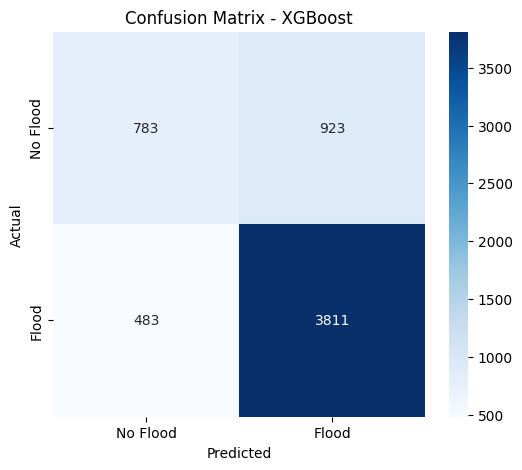

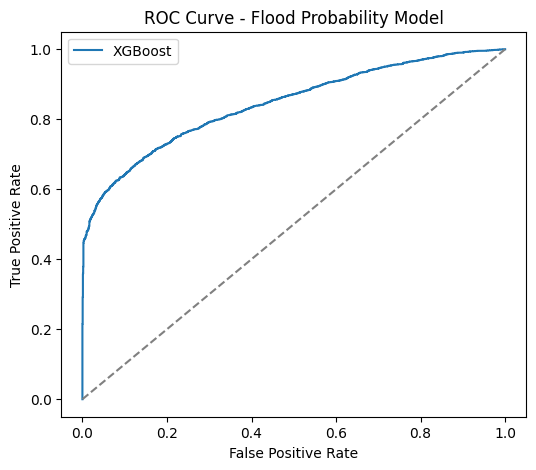

In [49]:
from sklearn.metrics import classification_report, confusion_matrix, roc_curve
import matplotlib.pyplot as plt
import seaborn as sns

preds = best_model.predict(X_test)
probs = best_model.predict_proba(X_test)[:,1]

print(classification_report(y_test, preds, target_names=['No Flood', 'Flood']))

cm = confusion_matrix(y_test, preds)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Flood','Flood'], yticklabels=['No Flood','Flood'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(f'Confusion Matrix - {best_model_name}')
plt.show()

# ROC Curve (since output is a probability score)
fpr, tpr, _ = roc_curve(y_test, probs)
plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f'{best_model_name}')
plt.plot([0,1],[0,1],'--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Flood Probability Model')
plt.legend()
plt.show()

## 8️⃣ Feature Importance

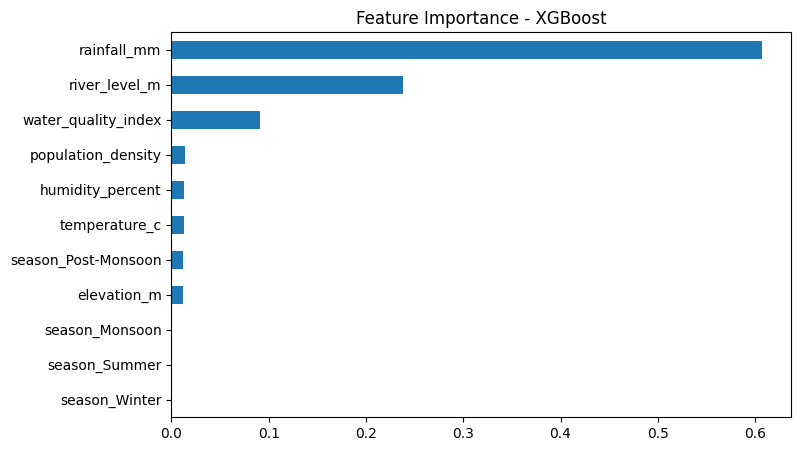

rainfall_mm            0.606855
river_level_m          0.237969
water_quality_index    0.091509
population_density     0.013741
humidity_percent       0.012903
temperature_c          0.012581
season_Post-Monsoon    0.012334
elevation_m            0.012108
season_Monsoon         0.000000
season_Summer          0.000000
season_Winter          0.000000
dtype: float32


In [50]:
importances = best_model.feature_importances_
feat_imp = pd.Series(importances, index=feature_cols).sort_values(ascending=False)

plt.figure(figsize=(8,5))
feat_imp.plot(kind='barh')
plt.title(f'Feature Importance - {best_model_name}')
plt.gca().invert_yaxis()
plt.show()

print(feat_imp)


## 9️⃣ Flood Probability Function
এটা backend API-তে ব্যবহার হবে — district-এর current rainfall/river_level/humidity/temperature দিলে flood probability + risk level রিটার্ন করবে।


In [51]:
def predict_flood(rainfall_mm, river_level_m, humidity_percent, temperature_c,
                   elevation_m=20, water_quality_index=70, population_density=1500,
                   season='Monsoon'):
    input_dict = {
        'rainfall_mm': rainfall_mm, 'river_level_m': river_level_m,
        'humidity_percent': humidity_percent, 'temperature_c': temperature_c,
        'elevation_m': elevation_m, 'water_quality_index': water_quality_index,
        'population_density': population_density
    }
    season_cols = [c for c in feature_cols if c.startswith('season_')]
    for col in season_cols:
        season_name = col.replace('season_', '')
        input_dict[col] = 1 if season_name == season else 0

    input_df = pd.DataFrame([input_dict])[feature_cols]
    flood_probability = best_model.predict_proba(input_df)[0][1]

    # simple rainfall-based severity hint (only meaningful if flood_probability is high)
    if rainfall_mm < 100:
        severity_hint = "Minor"
    elif rainfall_mm < 300:
        severity_hint = "Moderate"
    else:
        severity_hint = "Severe"

    return {
        'flood_probability': round(float(flood_probability), 4),
        'flood_risk_level': 'High' if flood_probability > 0.7 else ('Medium' if flood_probability > 0.4 else 'Low'),
        'likely_severity_if_flood': severity_hint
    }

print(predict_flood(rainfall_mm=180, river_level_m=8.5, humidity_percent=88, temperature_c=29,
                     elevation_m=5, season='Monsoon'))

{'flood_probability': 0.9992, 'flood_risk_level': 'High', 'likely_severity_if_flood': 'Moderate'}


## 🔟 Save Model (for Backend Integration)

In [52]:
import joblib
import os

SAVE_DIR = '/content/drive/MyDrive/FloodShieldAI/models'
os.makedirs(SAVE_DIR, exist_ok=True)

joblib.dump(best_model, f'{SAVE_DIR}/flood_prediction_model.pkl')
joblib.dump(le, f'{SAVE_DIR}/flood_level_label_encoder.pkl')
joblib.dump(feature_cols, f'{SAVE_DIR}/flood_model_features.pkl')

print(f"✅ Saved to: {SAVE_DIR}")
print("Files: flood_prediction_model.pkl, flood_level_label_encoder.pkl, flood_model_features.pkl")


✅ Saved to: /content/drive/MyDrive/FloodShieldAI/models
Files: flood_prediction_model.pkl, flood_level_label_encoder.pkl, flood_model_features.pkl


---
## ✅ পরের ধাপ
এই trained model (`flood_prediction_model.pkl`) FastAPI backend-এ load করে `/predict/flood` endpoint বানানো হবে।

**Model 2 (Disease Outbreak Prediction)** notebook-এ এই Model-1-এর output (flood probability) input হিসেবে ব্যবহার হবে।
